In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_train = pd.read_csv("../data/processed/X_train_clip.csv")
X_test = pd.read_csv("../data/processed/X_test_clip.csv")
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze()
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze()

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

Components needed for 90%: 21 (instead of 63 )


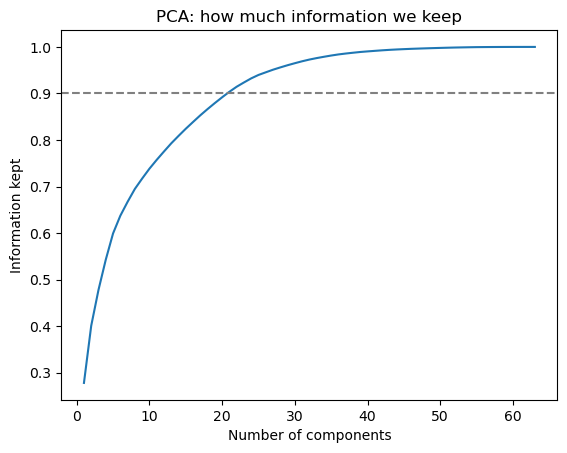

In [10]:
# PCA: how many summary features do we need to keep 90% of the information?
pca_full = PCA().fit(X_train_s)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n_comp = int(np.argmax(cum >= 0.90) + 1)
print("Components needed for 90%:", n_comp, "(instead of", X_train_s.shape[1], ")")

plt.plot(range(1, len(cum) + 1), cum)
plt.axhline(0.90, color="gray", linestyle="--")
plt.xlabel("Number of components")
plt.ylabel("Information kept")
plt.title("PCA: how much information we keep")
plt.show()

In [11]:
# Apply PCA with that number of components
pca = PCA(n_components=n_comp, random_state=42)
Z_train = pca.fit_transform(X_train_s)
Z_test = pca.transform(X_test_s)

k = 2  silhouette = 0.182
k = 3  silhouette = 0.321
k = 4  silhouette = 0.182
k = 5  silhouette = 0.167
k = 6  silhouette = 0.105
k = 7  silhouette = 0.097
k = 8  silhouette = 0.097


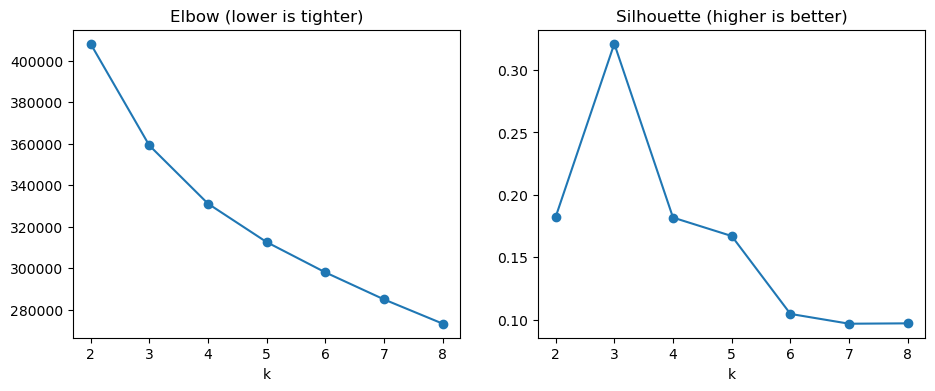

In [12]:
# Pick the number of groups (k) with the silhouette score
ks = range(2, 9)
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z_train)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Z_train, km.labels_, sample_size=3000, random_state=42))
    print("k =", k, " silhouette =", round(sils[-1], 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(ks), inertias, marker="o")
ax[0].set_title("Elbow (lower is tighter)")
ax[0].set_xlabel("k")
ax[1].plot(list(ks), sils, marker="o")
ax[1].set_title("Silhouette (higher is better)")
ax[1].set_xlabel("k")
plt.show()

In [13]:
# Choose k. Start with the best silhouette, but you may pick a nearby k if it gives more useful groups.
k = list(ks)[int(np.argmax(sils))]
print("Using k =", k)

kmeans = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z_train)
train_groups = kmeans.labels_
test_groups = kmeans.predict(Z_test)

profile = pd.DataFrame({"group": train_groups, "bankrupt": y_train.values})
summary = profile.groupby("group")["bankrupt"].agg(companies="count", bankrupt="sum", bankruptcy_rate="mean")
summary["bankruptcy_rate"] = (summary["bankruptcy_rate"] * 100).round(1)
print(summary)
print("Overall bankruptcy rate:", round(y_train.mean() * 100, 1), "%")

Using k = 3
       companies  bankrupt  bankruptcy_rate
group                                      
0           6419       280              4.4
1           1169        27              2.3
2            814        89             10.9
Overall bankruptcy rate: 4.7 %


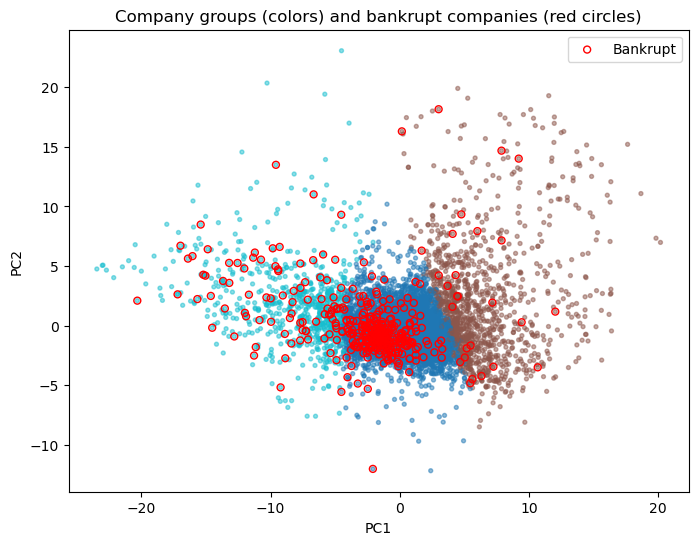

In [14]:
# Picture: companies on the first two summary features
plt.figure(figsize=(8, 6))
plt.scatter(Z_train[:, 0], Z_train[:, 1], c=train_groups, cmap="tab10", s=8, alpha=0.5)
bank = (y_train.values == 1)
plt.scatter(Z_train[bank, 0], Z_train[bank, 1], facecolors="none", edgecolors="red", s=25, label="Bankrupt")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Company groups (colors) and bankrupt companies (red circles)")
plt.legend()
plt.show()

In [15]:
# What makes each group different? Average of the most telling features per group
means = pd.DataFrame(X_train_s, columns=X_train.columns).groupby(train_groups).mean()
spread = means.std().sort_values(ascending=False).head(8).index
print(X_train[spread].groupby(train_groups).mean().round(3).T)

            0      1      2
Attr1   0.055  0.245 -0.268
Attr14  0.065  0.280 -0.267
Attr7   0.065  0.280 -0.267
Attr18  0.065  0.281 -0.267
Attr23  0.034  0.143 -0.279
Attr19  0.041  0.165 -0.276
Attr11  0.083  0.298 -0.227
Attr31  0.050  0.181 -0.266


In [16]:
# Does the same pattern show up on the test data?
test_profile = pd.DataFrame({"group": test_groups, "bankrupt": y_test.values})
test_summary = test_profile.groupby("group")["bankrupt"].agg(companies="count", bankrupt="sum", bankruptcy_rate="mean")
test_summary["bankruptcy_rate"] = (test_summary["bankruptcy_rate"] * 100).round(1)
print(test_summary)

       companies  bankrupt  bankruptcy_rate
group                                      
0           1614        69              4.3
1            296         5              1.7
2            191        25             13.1


In [17]:
# 1. Gaussian Mixture: try 2 to 8 groups
from sklearn.mixture import GaussianMixture

for n in range(2, 9):
    gmm = GaussianMixture(n_components=n, covariance_type="diag", random_state=42).fit(Z_train)
    labels = gmm.predict(Z_train)
    sil = silhouette_score(Z_train, labels, sample_size=3000, random_state=42)
    print("GMM groups =", n, " silhouette =", round(sil, 3), " BIC =", round(gmm.bic(Z_train)))

GMM groups = 2  silhouette = 0.206  BIC = 494582
GMM groups = 3  silhouette = -0.008  BIC = 479669
GMM groups = 4  silhouette = -0.02  BIC = 470202
GMM groups = 5  silhouette = -0.037  BIC = 467043
GMM groups = 6  silhouette = -0.051  BIC = 463702
GMM groups = 7  silhouette = -0.115  BIC = 458760
GMM groups = 8  silhouette = -0.106  BIC = 456981


In [18]:
# 2. Agglomerative: use a sample of 3000 companies (it is slow on all of them)
from sklearn.cluster import AgglomerativeClustering

rng = np.random.RandomState(42)
idx = rng.choice(len(Z_train), 3000, replace=False)
Z_s, y_s = Z_train[idx], y_train.values[idx]

for n in range(2, 9):
    labels = AgglomerativeClustering(n_clusters=n, linkage="ward").fit_predict(Z_s)
    print("Agglomerative groups =", n, " silhouette =", round(silhouette_score(Z_s, labels), 3))

Agglomerative groups = 2  silhouette = 0.233
Agglomerative groups = 3  silhouette = 0.245
Agglomerative groups = 4  silhouette = 0.211
Agglomerative groups = 5  silhouette = 0.201
Agglomerative groups = 6  silhouette = 0.128
Agglomerative groups = 7  silhouette = 0.111
Agglomerative groups = 8  silhouette = 0.116


In [19]:
# 3. DBSCAN: try a few "crowd distances" (eps)
from sklearn.cluster import DBSCAN

for eps in [2, 3, 4, 5, 6]:
    labels = DBSCAN(eps=eps, min_samples=10).fit_predict(Z_train)
    n_groups = len(set(labels)) - (1 if -1 in labels else 0)
    noise = (labels == -1).mean() * 100
    print("eps =", eps, " groups =", n_groups, " noise =", round(noise, 1), "%")

eps = 2  groups = 4  noise = 51.9 %
eps = 3  groups = 6  noise = 28.0 %
eps = 4  groups = 4  noise = 15.9 %
eps = 5  groups = 1  noise = 9.2 %
eps = 6  groups = 3  noise = 5.5 %


In [20]:
# 4. Pick one DBSCAN setting that gives a few groups and little noise, then check bankruptcy
eps_choice = 4   # change this after you see the output above

labels = DBSCAN(eps=eps_choice, min_samples=10).fit_predict(Z_train)
check = pd.DataFrame({"group": labels, "bankrupt": y_train.values})
out = check.groupby("group")["bankrupt"].agg(companies="count", bankrupt="sum", bankruptcy_rate="mean")
out["bankruptcy_rate"] = (out["bankruptcy_rate"] * 100).round(1)
print(out)   # group -1 means "noise" (the odd companies)

       companies  bankrupt  bankruptcy_rate
group                                      
-1          1338        95              7.1
 0          6997       299              4.3
 1            43         1              2.3
 2            15         0              0.0
 3             9         1             11.1
